# Presentation Charts — Flood Event Study

Regenerates the event-study results (CAPM market model, abnormal returns, CAR) and renders the
projector-styled charts used in the accompanying slide deck. Same method as
`Climate change event study.ipynb`: estimation window [-250,-20], event window [-20,+20],
STOXX Europe 600 benchmark. Charts are also written to `assets/` and stats to `results.json`.

In [1]:
%matplotlib inline
import json, warnings, os
import numpy as np, pandas as pd
import statsmodels.api as sm, scipy.stats as stats
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings("ignore")

BASE = os.getcwd()
ASSETS = os.path.join(BASE, "assets")
os.makedirs(ASSETS, exist_ok=True)

# palette (matches the presentation deck)
NAVY="#0B2A3A"; OCEAN="#12658F"; AMBER="#E0842A"; GREEN="#2E8B6E"; REDNEG="#B23A3A"
INK="#17323F"; MUTED="#5C6E79"; LINE="#D4DEE4"; PANEL="#EEF4F7"
ALLIANZ="#1F6FB2"; MUNICH="#E0842A"; SWISS="#B23A3A"
CO = {"ALV.DE":ALLIANZ, "MUV2.DE":MUNICH, "SREN.SW":SWISS}
NAME = {"ALV.DE":"Allianz", "MUV2.DE":"Munich Re", "SREN.SW":"Swiss Re"}

plt.rcParams.update({
    "font.family":"DejaVu Sans", "font.size":15, "axes.titlesize":18,
    "axes.labelsize":15, "xtick.labelsize":13, "ytick.labelsize":13,
    "legend.fontsize":13, "axes.edgecolor":MUTED, "axes.linewidth":1.0,
    "figure.facecolor":"white", "axes.facecolor":"white", "savefig.facecolor":"white",
})
def clean_ax(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(True, axis="y", color=LINE, linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
pct = FuncFormatter(lambda v,_: f"{v*100:.0f}%")

## Load and cache prices

In [2]:
tickers=["ALV.DE","MUV2.DE","SREN.SW"]; benchmark=["^STOXX"]
CACHE=os.path.join(BASE,"prices_cache.parquet")
if os.path.exists(CACHE):
    clean=pd.read_parquet(CACHE); print("loaded price cache")
else:
    clean=pd.DataFrame()
    for t in tickers+benchmark:
        d=yf.download(t, start="1998-01-01", end="2021-12-31", progress=False, auto_adjust=False)
        if d.empty:
            print("WARN empty",t); continue
        if isinstance(d.columns,pd.MultiIndex): d.columns=d.columns.get_level_values(0)
        d.columns=d.columns.str.title()
        clean[t]= d["Adj Close"] if "Adj Close" in d.columns else d["Close"]
    clean.to_parquet(CACHE)
stock_prices=clean[tickers].dropna(); market_prices=clean[benchmark].dropna()
stock_returns=np.log(stock_prices/stock_prices.shift(1)).dropna()
market_returns=np.log(market_prices/market_prices.shift(1)).dropna()
idx=stock_returns.index.intersection(market_returns.index)
stock_returns=stock_returns.loc[idx]; market_returns=market_returns.loc[idx]
print("aligned trading days:", len(stock_returns), "start", stock_returns.index[0].date())

loaded price cache
aligned trading days: 4435 start 2004-04-27


## Flood events and the event-study loop (CAPM, AR, CAR)

In [3]:
ev=pd.read_csv(os.path.join(BASE,"HANZE_events.csv"))
ev["Start date"]=pd.to_datetime(ev["Start date"],errors="coerce")
ev["Year"]=pd.to_numeric(ev["Year"],errors="coerce")
ev["Losses (2020 euro)"]=pd.to_numeric(ev["Losses (2020 euro)"],errors="coerce")
per=ev[(ev["Year"]>=2000)&(ev["Year"]<=2020)]
ordered=per.sort_values("Losses (2020 euro)",ascending=False)

def nearest(td, ti):
    if td.tzinfo is not None and ti.tz is None: td=td.replace(tzinfo=None)
    return ti[ti.get_indexer([td],method="nearest")[0]]
def capm(y_all,x_all,edate):
    i=y_all.index.get_loc(edate); s,e=i-250,i-20
    y=y_all.iloc[s:e]; x=sm.add_constant(x_all.iloc[s:e])
    return sm.OLS(y,x).fit()
def car_stats(model,y_all,x_all,edate):
    i=y_all.index.get_loc(edate); s,e=i-20,i+21
    actual=y_all.iloc[s:e]; mw=sm.add_constant(x_all.iloc[s:e])
    exp=model.predict(mw); ar=actual-exp; car=ar.cumsum()
    rstd=np.sqrt(model.mse_resid)
    se=rstd*np.sqrt(np.arange(1,len(car)+1))
    t=car.iloc[-1]/se[-1]; p=(1-stats.norm.cdf(abs(t)))*2
    return ar.values, car.values, se, t, p

events=[]; valid=0
for _,f in ordered.iterrows():
    if valid>=3: break
    try:
        td=nearest(f["Start date"], stock_returns.index)
        i=stock_returns.index.get_loc(td)
        if i-250<0: continue
    except KeyError: continue
    rec={"country":f["Country name"],"year":int(f["Year"]),
         "date":f["Start date"].strftime("%Y-%m-%d"),
         "trading_date":pd.Timestamp(td).strftime("%Y-%m-%d"),
         "loss_bn":round(f["Losses (2020 euro)"]/1e9,2),
         "fatalities":int(f["Fatalities"]) if not pd.isna(f["Fatalities"]) else None,
         "type":f["Type"],"series":{}}
    for tk in tickers:
        m=capm(stock_returns[tk],market_returns[benchmark[0]],td)
        ar,car,se,t,p=car_stats(m,stock_returns[tk],market_returns[benchmark[0]],td)
        rec["series"][tk]={"beta":round(float(m.params.iloc[1]),3),
            "alpha":round(float(m.params.iloc[0]),5),
            "car":[round(float(c),5) for c in car],
            "se":[round(float(s),5) for s in se],
            "car20":round(float(car[-1]),4),"t":round(float(t),2),"p":round(float(p),3)}
    events.append(rec); valid+=1
    print(f"{rec['country']} {rec['year']}: "+", ".join(f"{NAME[t]} {rec['series'][t]['car20']:+.4f}(t={rec['series'][t]['t']},p={rec['series'][t]['p']})" for t in tickers))

results={"n_days":len(stock_returns),"start":str(stock_returns.index[0].date()),
         "n_events_period":int(len(per)),"n_events_total":int(len(ev)),
         "events":events}
json.dump(results, open(os.path.join(BASE,"results.json"),"w"), indent=2)
xr=np.arange(-20,21)

Germany 2013: Allianz +0.0645(t=1.21,p=0.228), Munich Re -0.0484(t=-0.92,p=0.357), Swiss Re -0.0617(t=-1.02,p=0.31)
United Kingdom 2007: Allianz +0.0253(t=0.5,p=0.617), Munich Re -0.0457(t=-0.92,p=0.356), Swiss Re -0.0994(t=-1.86,p=0.063)
Poland 2010: Allianz +0.0315(t=0.47,p=0.642), Munich Re -0.0824(t=-1.32,p=0.187), Swiss Re +0.0293(t=0.28,p=0.776)


## Chart 1 — Which floods we analyse
Ranked by economic loss; blue = analysed, amber = excluded (predates the 2004 price sample), grey = smaller floods in-sample.

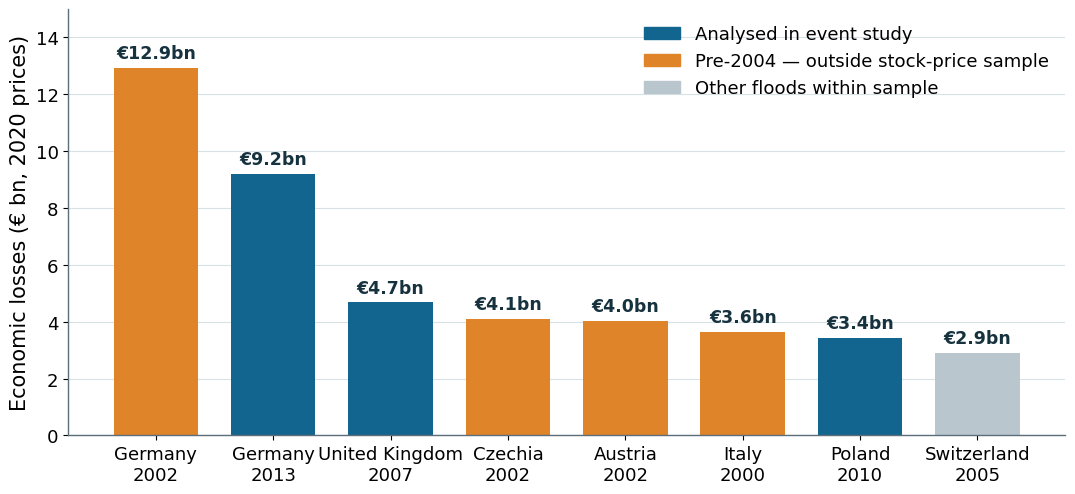

In [4]:
top=ordered.head(8)[["Country name","Year","Losses (2020 euro)"]].copy()
top["lab"]=top["Country name"]+"\n"+top["Year"].astype(int).astype(str)
top["bn"]=top["Losses (2020 euro)"]/1e9
analyzed={(e["country"],e["year"]) for e in events}
cols=[]
for _,r in top.iterrows():
    k=(r["Country name"],int(r["Year"]))
    cols.append(OCEAN if k in analyzed else (AMBER if int(r["Year"])<2004 else "#B9C6CE"))
fig,ax=plt.subplots(figsize=(11,5.2))
b=ax.bar(range(len(top)),top["bn"],color=cols,width=0.72)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top["lab"])
for i,(rect,v) in enumerate(zip(b,top["bn"])):
    ax.text(rect.get_x()+rect.get_width()/2, v+0.2, f"€{v:.1f}bn", ha="center",
            va="bottom", fontsize=12.5, fontweight="bold", color=INK)
ax.set_ylabel("Economic losses (€ bn, 2020 prices)"); clean_ax(ax)
ax.set_ylim(0,15)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=OCEAN,label="Analysed in event study"),
                   Patch(color=AMBER,label="Pre-2004 — outside stock-price sample"),
                   Patch(color="#B9C6CE",label="Other floods within sample")],
          loc="upper right", frameon=False)
plt.tight_layout(); plt.savefig(f"{ASSETS}/flood_losses.png",dpi=200)

## Chart 2 — CAPM fit
Allianz vs. STOXX 600 daily log-returns, estimation window ending 20 days before the Germany 2013 floods.

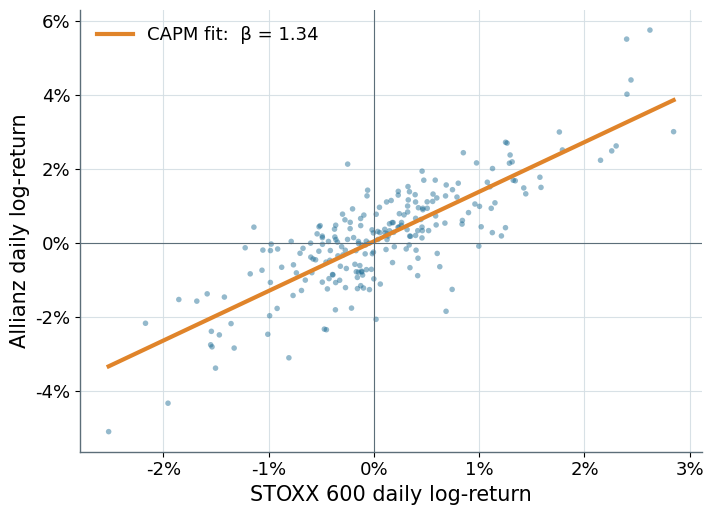

In [5]:
g13=[e for e in events if e["country"]=="Germany" and e["year"]==2013][0]
td=pd.Timestamp(g13["trading_date"]); i=stock_returns.index.get_loc(td)
ys=stock_returns["ALV.DE"].iloc[i-250:i-20].values
xs=market_returns["^STOXX"].iloc[i-250:i-20].values
m=g13["series"]["ALV.DE"]
fig,ax=plt.subplots(figsize=(7.4,5.4))
ax.scatter(xs,ys,s=16,color=OCEAN,alpha=0.45,edgecolors="none")
xx=np.linspace(xs.min(),xs.max(),50)
ax.plot(xx,m["alpha"]+m["beta"]*xx,color=AMBER,linewidth=3,
        label=f"CAPM fit:  β = {m['beta']:.2f}")
ax.axhline(0,color=MUTED,lw=0.8); ax.axvline(0,color=MUTED,lw=0.8)
ax.set_xlabel("STOXX 600 daily log-return"); ax.set_ylabel("Allianz daily log-return")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
clean_ax(ax); ax.grid(True,axis="x",color=LINE,lw=0.8,alpha=0.9)
ax.legend(loc="upper left",frameon=False)
plt.tight_layout(); plt.savefig(f"{ASSETS}/capm_fit.png",dpi=200)

## Chart 3 — How to read a CAR chart
Swiss Re after the UK 2007 floods: the line is CAR, the band is the 95% CI, the vertical marker is the event day.

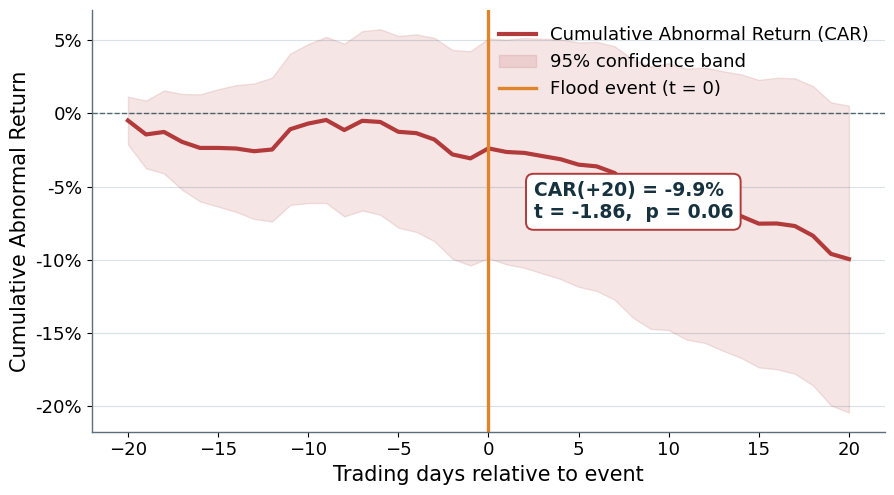

In [6]:
uk=[e for e in events if e["country"]=="United Kingdom"][0]
s=uk["series"]["SREN.SW"]; car=np.array(s["car"]); se=np.array(s["se"])
fig,ax=plt.subplots(figsize=(9.2,5.2))
ax.plot(xr,car,color=SWISS,lw=3,label="Cumulative Abnormal Return (CAR)")
ax.fill_between(xr,car-1.96*se,car+1.96*se,color=SWISS,alpha=0.13,label="95% confidence band")
ax.axhline(0,color=INK,ls="--",lw=1,alpha=0.7)
ax.axvline(0,color=AMBER,lw=2.4,label="Flood event (t = 0)")
ax.set_xlabel("Trading days relative to event"); ax.set_ylabel("Cumulative Abnormal Return")
ax.yaxis.set_major_formatter(pct); clean_ax(ax)
ax.annotate(f"CAR(+20) = {s['car20']*100:.1f}%\nt = {s['t']:.2f},  p = {s['p']:.2f}",
            xy=(20,car[-1]), xytext=(2.5,car.min()*0.72),
            fontsize=13.5, color=INK, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.4",fc="white",ec=SWISS,lw=1.4))
ax.legend(loc="upper right",frameon=False)
plt.tight_layout(); plt.savefig(f"{ASSETS}/car_readguide.png",dpi=200)

## Charts 4–6 — CAR by event, all three insurers overlaid
Germany 2013, United Kingdom 2007, Poland 2010.

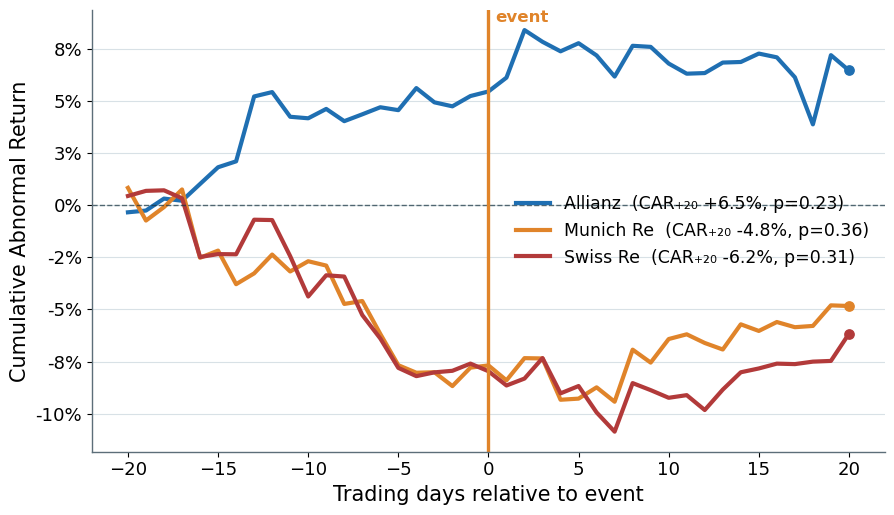

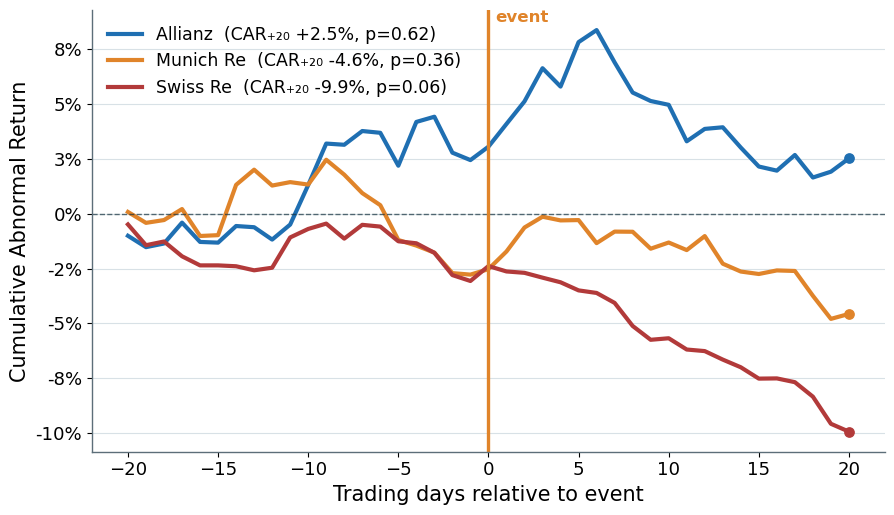

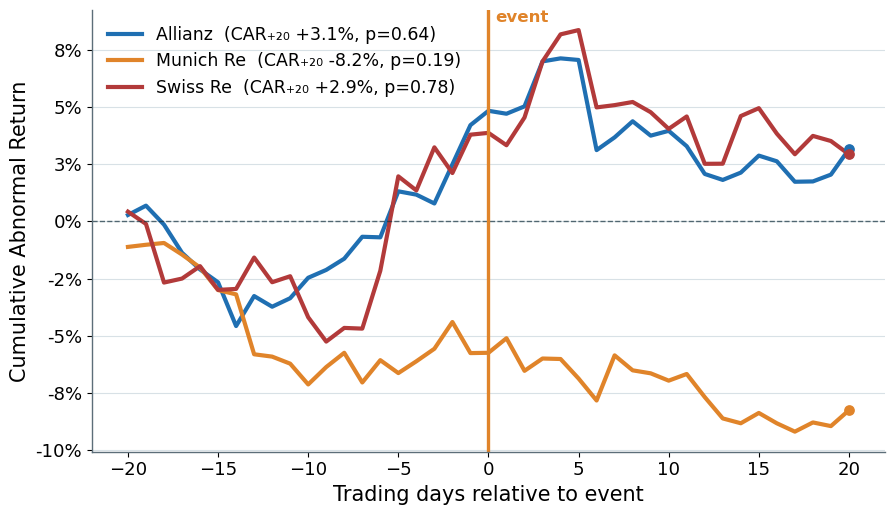

In [7]:
def event_chart(e, fname):
    fig,ax=plt.subplots(figsize=(9.2,5.4))
    for tk in tickers:
        s=e["series"][tk]; car=np.array(s["car"])
        ax.plot(xr,car,color=CO[tk],lw=3,label=f"{NAME[tk]}  (CAR₊₂₀ {s['car20']*100:+.1f}%, p={s['p']:.2f})")
        ax.scatter([20],[car[-1]],color=CO[tk],s=45,zorder=5)
    ax.axhline(0,color=INK,ls="--",lw=1,alpha=0.7)
    ax.axvline(0,color=AMBER,lw=2.4)
    ax.text(0.4,ax.get_ylim()[1],"event",color=AMBER,fontsize=12,va="top",fontweight="bold")
    ax.set_xlabel("Trading days relative to event"); ax.set_ylabel("Cumulative Abnormal Return")
    ax.yaxis.set_major_formatter(pct); clean_ax(ax)
    ax.legend(loc="best",frameon=False,fontsize=12.5)
    plt.tight_layout(); plt.savefig(f"{ASSETS}/{fname}",dpi=200)
    plt.show()
for e in events:
    key={"Germany":"car_germany2013","United Kingdom":"car_uk2007","Poland":"car_poland2010"}[e["country"]]
    event_chart(e,f"{key}.png")

## Chart 7 — Cumulative abnormal return at t = +20, all events
`*` marks p < 0.10. None reach the conventional 5% level.

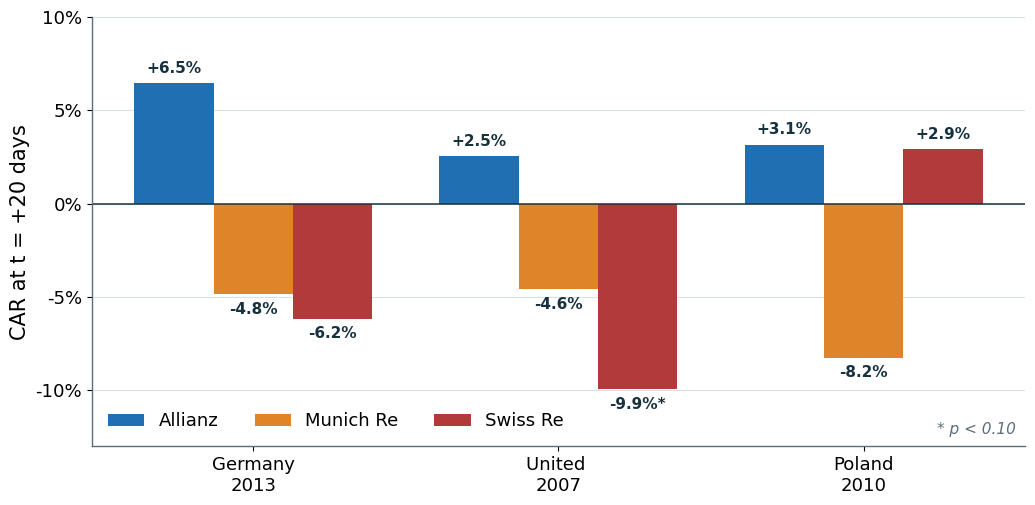

In [8]:
labels=[f"{e['country'][:7]}\n{e['year']}" for e in events]
fig,ax=plt.subplots(figsize=(10.6,5.3))
w=0.26; x=np.arange(len(events))
for j,tk in enumerate(tickers):
    vals=[e["series"][tk]["car20"] for e in events]
    bars=ax.bar(x+(j-1)*w, vals, w, color=CO[tk], label=NAME[tk])
    for rect,v,e in zip(bars,vals,events):
        star="*" if e["series"][tk]["p"]<0.10 else ""
        ax.text(rect.get_x()+w/2, v+(0.004 if v>=0 else -0.004), f"{v*100:+.1f}%{star}",
                ha="center", va="bottom" if v>=0 else "top", fontsize=11, fontweight="bold", color=INK)
ax.axhline(0,color=INK,lw=1.1)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("CAR at t = +20 days"); ax.yaxis.set_major_formatter(pct)
clean_ax(ax); ax.set_ylim(-0.13,0.10)
ax.legend(loc="lower left",frameon=False,ncol=3)
ax.text(0.99,0.03,"* p < 0.10", transform=ax.transAxes, ha="right", fontsize=11, color=MUTED, style="italic")
plt.tight_layout(); plt.savefig(f"{ASSETS}/car_endpoints.png",dpi=200)

---
Charts are written to `assets/` (PNG, 200 dpi) and summary statistics to `results.json` for reuse in the presentation deck.